In [34]:
import os
import sys
import pandas as pd
import glob
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from utils.plotting import plot_movement_data
from utils.plotting import plot_movement_data_3d
from utils.helper_functions import get_smart_retail_dataset
from utils.constants import Configs
from utils.helper_functions import load_outlier_data

## Get Inliers

In [35]:
# left_files_path = glob.glob(f'{Configs.SEPARATED_INLIERS_UMAP_DIR}/*_left_Tasks.csv')
# right_files_path = glob.glob(f'{Configs.SEPARATED_INLIERS_UMAP_DIR}/*_right_Tasks.csv')


# inliers desktop
left_files_path = glob.glob('/home/hugo-guimar-es/Downloads/Inliers_SmartRetail/*_left_Tasks.csv')
right_files_path = glob.glob('/home/hugo-guimar-es/Downloads/Inliers_SmartRetail/*_right_Tasks.csv')

df_inliers = get_smart_retail_dataset(
    left_files=left_files_path,
    right_files=right_files_path
)

# dataset normal
df_raw = get_smart_retail_dataset()

Loading and fusing bimanual files...
Loading and fusing bimanual files...


In [36]:
print("\n--- Fusing Outliers into a singular Ground Truth ---")

# Load the known outliers from the csv
outliers_left_csv, total_known_outliers_left = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_LEFT_PATH)
outliers_right_csv, total_known_outliers_right = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_RIGHT_PATH)


outliers_bimanual = pd.concat([outliers_left_csv, outliers_right_csv])
total_known_outliers = len(outliers_bimanual)

# O drop_duplicates garante que se o sub 13 falhou com as duas mãos, conta como 1 erro
outliers_bimanual = outliers_bimanual.drop_duplicates(subset=['sub', 'repID']).copy()
total_known_outliers = len(outliers_bimanual)

print(f"Total de OUTLIERS BIMANUAIS (Ground Truth): {total_known_outliers}")


--- Fusing Outliers into a singular Ground Truth ---
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_left.csv
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_right.csv
Total de OUTLIERS BIMANUAIS (Ground Truth): 24


### Discard Subject 13

In [37]:
# Discard from dataset
df_inliers.drop(df_inliers[df_inliers['sub']== 13].index, inplace=True)

# Discard from outliers csv
outliers_bimanual.drop(outliers_bimanual[outliers_bimanual['sub'] == 13].index, inplace=True)
outliers_bimanual[outliers_bimanual['sub'] == 13]

,sub,repID


In [38]:
# Separar em 3 DataFrames independentes (usando .get() para não dar erro se faltar algum)
df_inliers_pick = df_inliers[df_inliers['movLabel'] == 'Pick']
df_inliers_place = df_inliers[df_inliers['movLabel'] == 'Place']
df_inliers_park = df_inliers[df_inliers['movLabel'] == 'Park']

--- Configuração do Gráfico para Park ---
Linhas de Inliers (Trajetórias Normais): 12923
Linhas de Outliers Detetados (Vão aparecer a Vermelho): 0

--- A gerar gráfico 3D para a Mão ESQUERDA ---


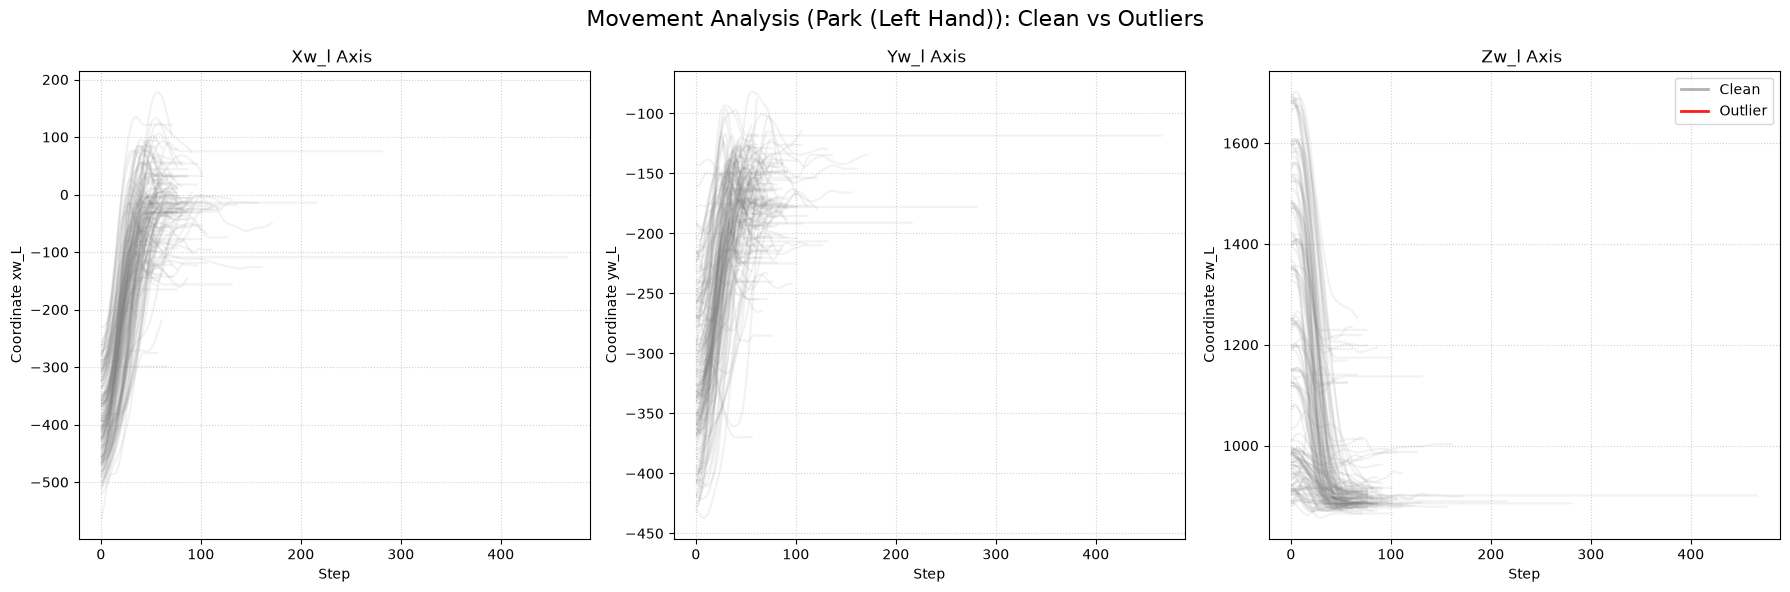


--- A gerar gráfico 3D para a Mão DIREITA ---


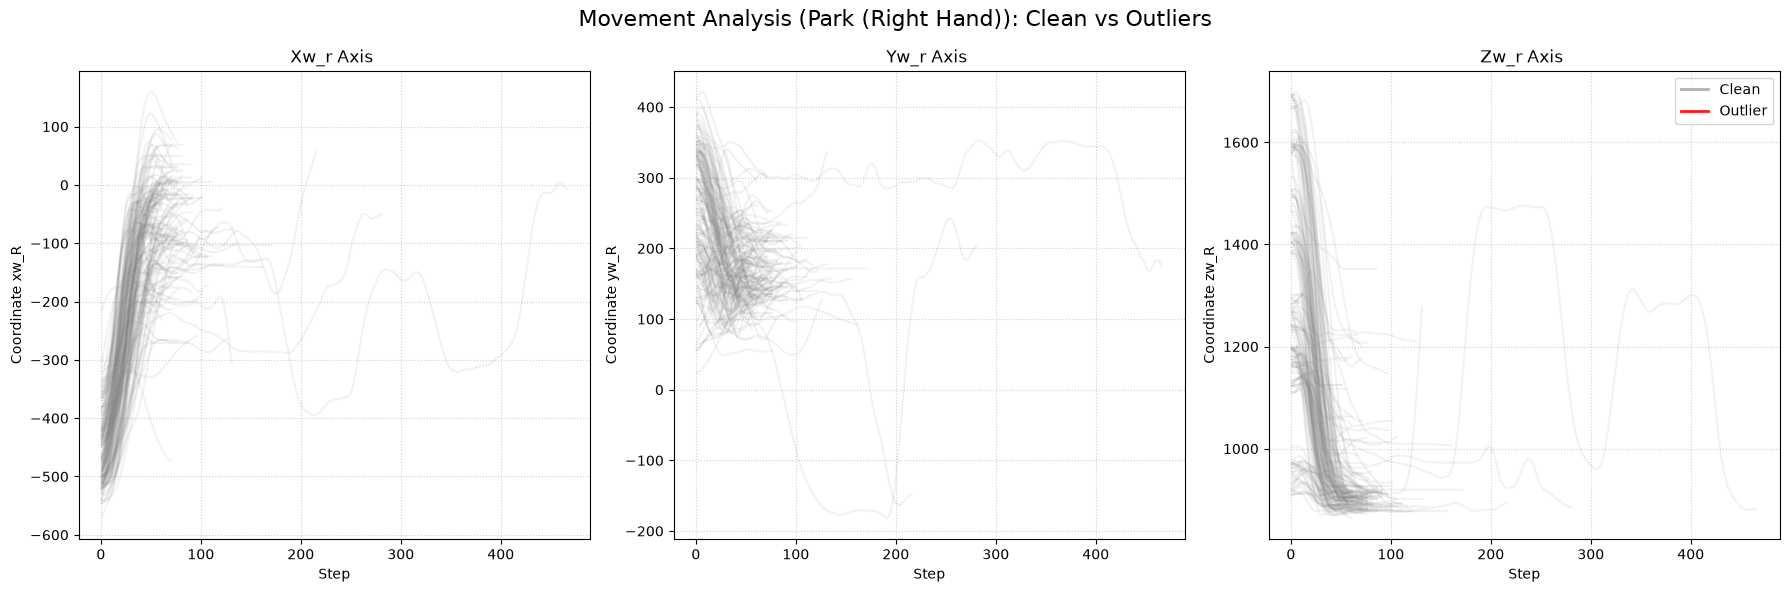

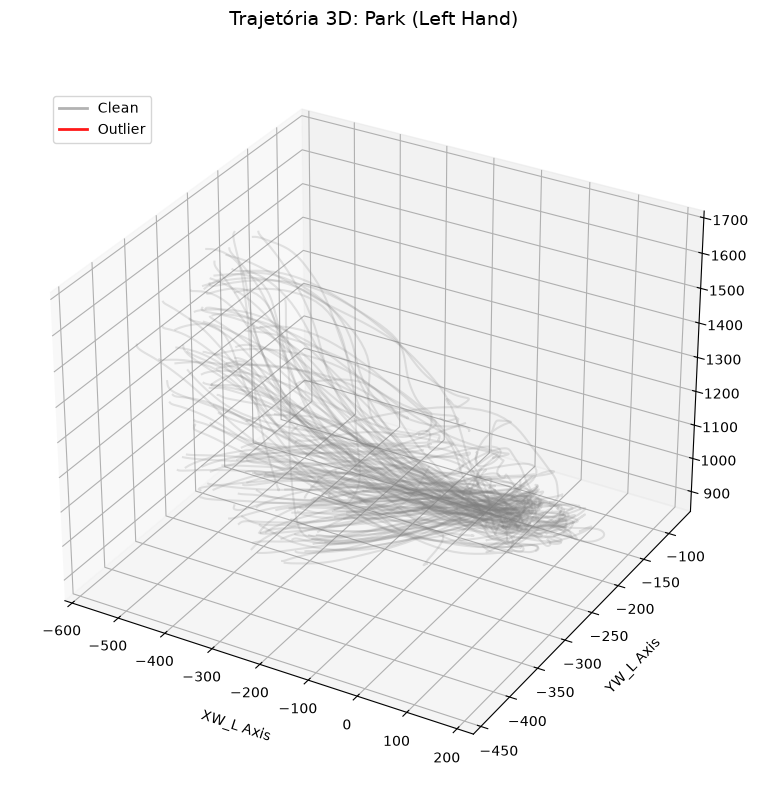

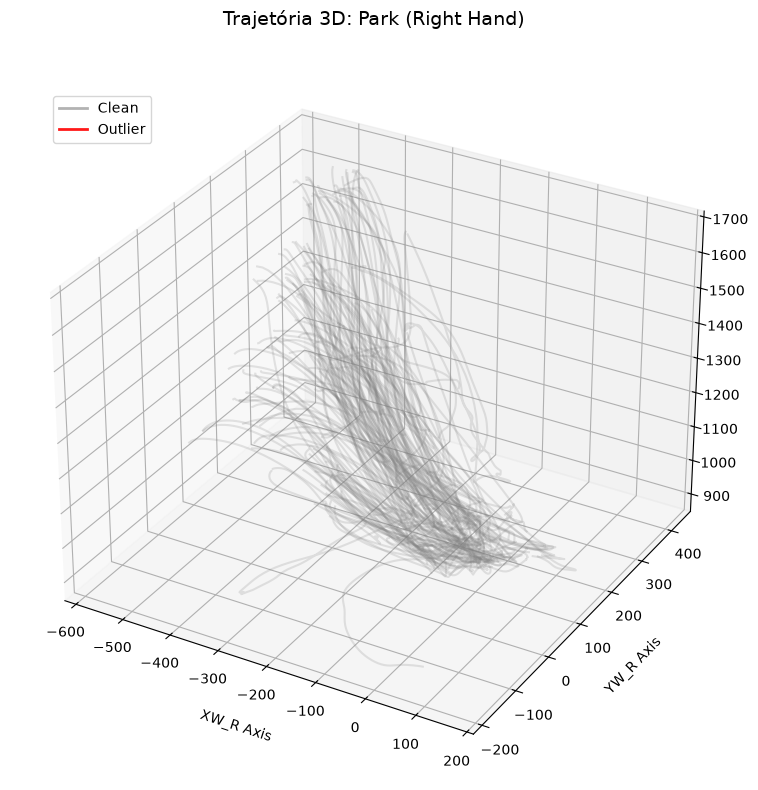

In [39]:
# ==========================================
# DIAGNÓSTICO E VISUALIZAÇÃO DE CONFIGURAÇÃO
# ==========================================

TARGET_MOV = 'Park' 

if TARGET_MOV == 'Pick':
    inliers_temp = df_inliers_pick.copy()
elif TARGET_MOV == 'Park':
    inliers_temp = df_inliers_park.copy()
elif TARGET_MOV == 'Place':
    inliers_temp = df_inliers_place.copy()
else:
    raise ValueError(f"Invalid Movement Selection: {TARGET_MOV}. Choose from 'Pick', 'Park', or 'Place'.")

# Criar a chave 'temp_key' para agrupar as séries temporais nos inliers
inliers_temp['temp_key'] = inliers_temp['sub'].astype(str) + "_" + \
                           inliers_temp['repID'].astype(str) + "_" + \
                           inliers_temp['movID'].astype(str)

# 3. EXTRAIR OS OUTLIERS VERDADEIROS
# Vamos ao teu DataFrame original ('df' que carregou o filtered_data.csv completo)
df_original_mov = df_inliers[df_inliers['movLabel'] == TARGET_MOV].copy()

# Criar a mesma chave 'temp_key' no DataFrame original
df_original_mov['temp_key'] = df_original_mov['sub'].astype(str) + "_" + \
                              df_original_mov['repID'].astype(str) + "_" + \
                              df_original_mov['movID'].astype(str)

# Os outliers detetados são as linhas que estão no original mas NÃO estão nos inliers limpos
outliers_temp = df_original_mov[~df_original_mov['temp_key'].isin(inliers_temp['temp_key'])].copy()
from utils.constants import Configs
from utils.helper_functions import load_outlier_data
print(f"--- Configuração do Gráfico para {TARGET_MOV} ---")
print(f"Linhas de Inliers (Trajetórias Normais): {len(inliers_temp)}")
print(f"Linhas de Outliers Detetados (Vão aparecer a Vermelho): {len(outliers_temp)}")

print("\n--- A gerar gráfico 3D para a Mão ESQUERDA ---")
plot_movement_data(
    clean_data=inliers_temp,       
    outlier_data=outliers_temp,  
    target_movement=f"{TARGET_MOV} (Left Hand)",
    axis_names=['xw_L', 'yw_L', 'zw_L'] 
)

print("\n--- A gerar gráfico 3D para a Mão DIREITA ---")
plot_movement_data(
    clean_data=inliers_temp,       
    outlier_data=outliers_temp,  
    target_movement=f"{TARGET_MOV} (Right Hand)",
    axis_names=['xw_R', 'yw_R', 'zw_R']
)

plot_movement_data_3d(
    clean_data=inliers_temp,       
    outlier_data=outliers_temp,  
    target_movement=f"{TARGET_MOV} (Left Hand)",
    axis_names=['xw_L', 'yw_L', 'zw_L']
)
plot_movement_data_3d(
    clean_data=inliers_temp,       
    outlier_data=outliers_temp,  
    target_movement=f"{TARGET_MOV} (Right Hand)",
    axis_names=['xw_R', 'yw_R', 'zw_R']
)

### Ver quais séries foram retiradas
Quero validar se eu descartei a série inteira (todos os movimentos "Pick", "Park" e "Place") se algum deles for considerado outlier

In [40]:
# Definir o que constitui uma repetição "perfeita" e completa
expected_movs = ['Pick', 'Park', 'Place']
num_expected_movs = len(expected_movs)

# Assumimos que o df_final é o teu dataset limpo (ex: df_gold_standard)
df_final = df_inliers # Substitui pelo nome do teu dataframe se for diferente

for sub in sorted(df_final['sub'].unique()):
    print(f"Start Analyzing Subject {sub}")
    
    # Isolar os dados do sujeito (Torna os loops internos muito mais rápidos)
    df_sub = df_final[df_final['sub'] == sub]
    
    last_repID = -1

    for repID in sorted(df_sub['repID'].unique()):
        
        # Isolar os dados desta repetição específica
        df_rep = df_sub[df_sub['repID'] == repID]
        
        # ====================================================================
        # 1. VALIDAÇÃO DE INTEGRIDADE (A Guilhotina falhou?)
        # ====================================================================
        movimentos_presentes = df_rep['movLabel'].unique()
        
        if len(movimentos_presentes) != num_expected_movs:
            print(f"  🚨 ALERTA CRÍTICO: Sujeito {sub}, RepID {repID} está corrompido/incompleto!")
            print(f"     -> Sobreviveram apenas os movimentos: {movimentos_presentes}")
            print(f"     -> A repetição não foi apagada por completo. Verifica a Guilhotina!")
        
        # ====================================================================
        # 2. VALIDAÇÃO DE SEQUÊNCIA (Saltos no repID)
        # ====================================================================
        if repID == 9:
            pass # A tua regra específica para ignorar o 9
        elif last_repID != -1 and repID != (last_repID + 1):
            print(f"  ⚠️ Aviso: Salto de repID no Sub {sub}. Esperava {last_repID + 1}, mas detetou {repID}.")
            
        last_repID = repID

Start Analyzing Subject 1
  ⚠️ Aviso: Salto de repID no Sub 1. Esperava 4, mas detetou 5.
Start Analyzing Subject 2
  ⚠️ Aviso: Salto de repID no Sub 2. Esperava 3, mas detetou 4.
Start Analyzing Subject 3
Start Analyzing Subject 4
Start Analyzing Subject 5
Start Analyzing Subject 6
  ⚠️ Aviso: Salto de repID no Sub 6. Esperava 4, mas detetou 5.
Start Analyzing Subject 7
Start Analyzing Subject 8
Start Analyzing Subject 9
Start Analyzing Subject 10
Start Analyzing Subject 11
  ⚠️ Aviso: Salto de repID no Sub 11. Esperava 3, mas detetou 4.
Start Analyzing Subject 12
Start Analyzing Subject 14
  ⚠️ Aviso: Salto de repID no Sub 14. Esperava 4, mas detetou 5.
Start Analyzing Subject 15
Start Analyzing Subject 16
Start Analyzing Subject 17
Start Analyzing Subject 18
Start Analyzing Subject 19


## Análise de Número de repetições por sujeito

<Axes: xlabel='sub', ylabel='count'>

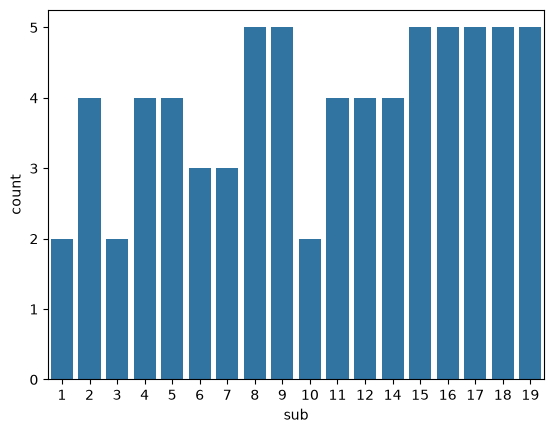

In [41]:
df_repID_distinct = df_inliers.drop_duplicates(subset=['sub', 'repID']).copy()
counts = df_repID_distinct.groupby('sub')['repID'].count().reset_index(name='count')

sns.barplot(
    data=counts,
    x='sub',
    y='count',
)

In [42]:
print("RepID count: {}".format(counts['count'].sum()))

RepID count: 71


## Análise do número de repetições por sub, repID e movID
Se tiver a analisar os inliers mal saem do plot validation, devem ter o mesmo número de steps, caso passem pelo Convert_original_steps.ipynb devem ter o mesmo número que os dados originais. 

In [43]:
def read_files(files):
    dfs = []

    for lf in files:
        df = pd.read_csv(lf, delimiter=';')
        dfs.append(df)

    df = pd.concat(dfs, ignore_index=True)
    df = df.sort_values(by=['sub', 'repID', 'movID', 'step']).reset_index(drop=True)
    df = df.ffill().bfill()

    mapa_mov = {0: 'Pick', 1: 'Place', 6: 'Park'} 
    df['movLabel'] = df['movType'].map(mapa_mov)
    
    return df

def count_trajectory_steps(df: pd.DataFrame, prefix: str) -> pd.DataFrame:
    """
    Groups the dataframe by trajectory identifiers and counts the number of steps (rows).
    Returns a DataFrame with the trajectory IDs and their respective step counts.
    """
    # .size() counts the number of rows per group (which corresponds to the number of steps)
    counts = df.groupby(['sub', 'repID', 'movID']).size().reset_index(name=f'{prefix}_steps')
    return counts

def plot_arm_steps_comparison(df_orig_left: pd.DataFrame, df_orig_right: pd.DataFrame, 
                              df_padded_left: pd.DataFrame, df_padded_right: pd.DataFrame):
    """
    Plots a side-by-side comparison of Left vs Right arm steps.
    Plot 1: Original Inliers (Raw data, varying lengths).
    Plot 2: Exported Inliers (Padded data, perfectly synced).
    """
    print("\n--- Calculating steps for Left and Right arms ---")

    # Count steps for original data
    orig_left_counts = count_trajectory_steps(df_orig_left, 'raw_left')
    orig_right_counts = count_trajectory_steps(df_orig_right, 'raw_right')
    df_raw = pd.merge(orig_left_counts, orig_right_counts, on=['sub', 'repID', 'movID'], how='inner')

    # Count steps for padded data
    padded_left_counts = count_trajectory_steps(df_padded_left, 'padded_left')
    padded_right_counts = count_trajectory_steps(df_padded_right, 'padded_right')
    df_padded = pd.merge(padded_left_counts, padded_right_counts, on=['sub', 'repID', 'movID'], how='inner')

    # Merge all counts to align them and find the global max for plotting axes
    df_all = pd.merge(df_raw, df_padded, on=['sub', 'repID', 'movID'], how='inner')

    max_val = max(
        df_all['raw_left_steps'].max(),
        df_all['raw_right_steps'].max(),
        df_all['padded_left_steps'].max(),
        df_all['padded_right_steps'].max()
    ) + 10

    # Generate Subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    # --- Plot 1: Original Inliers Data (Raw Unpadded Data) ---
    ax1.scatter(
        df_all['raw_left_steps'], 
        df_all['raw_right_steps'], 
        alpha=0.6, color='red', edgecolor='k', s=60
    )
    
    ax1.plot([0, max_val], [0, max_val], 'k--', label='Perfect Sync (Left = Right)')
    
    ax1.set_title('Original Inliers (Raw Unpadded Data)', fontsize=12)
    ax1.set_xlabel('Left Arm (Number of Steps)')
    ax1.set_ylabel('Right Arm (Number of Steps)')
    ax1.set_xlim(0, max_val)
    ax1.set_ylim(0, max_val)
    ax1.legend()
    ax1.grid(True, linestyle=':', alpha=0.7)

    # --- Plot 2: Exported Inliers Data (Padded/Interpolated) ---
    ax2.scatter(
        df_all['padded_left_steps'], 
        df_all['padded_right_steps'], 
        alpha=0.6, color='blue', edgecolor='k', s=60
    )
    
    ax2.plot([0, max_val], [0, max_val], 'k--', label='Perfect Sync (Left = Right)')
    
    ax2.set_title('Exported Inliers (Padded for ML Pipeline)', fontsize=12)
    ax2.set_xlabel('Left Arm (Number of Steps)')
    ax2.set_ylabel('Right Arm (Number of Steps)')
    ax2.set_xlim(0, max_val)
    ax2.set_ylim(0, max_val)
    ax2.legend()
    ax2.grid(True, linestyle=':', alpha=0.7)

    plt.suptitle('Trajectory Length Comparison: Left vs Right Arm', fontsize=16)
    plt.tight_layout()
    plt.show()


--- Calculating steps for Left and Right arms ---


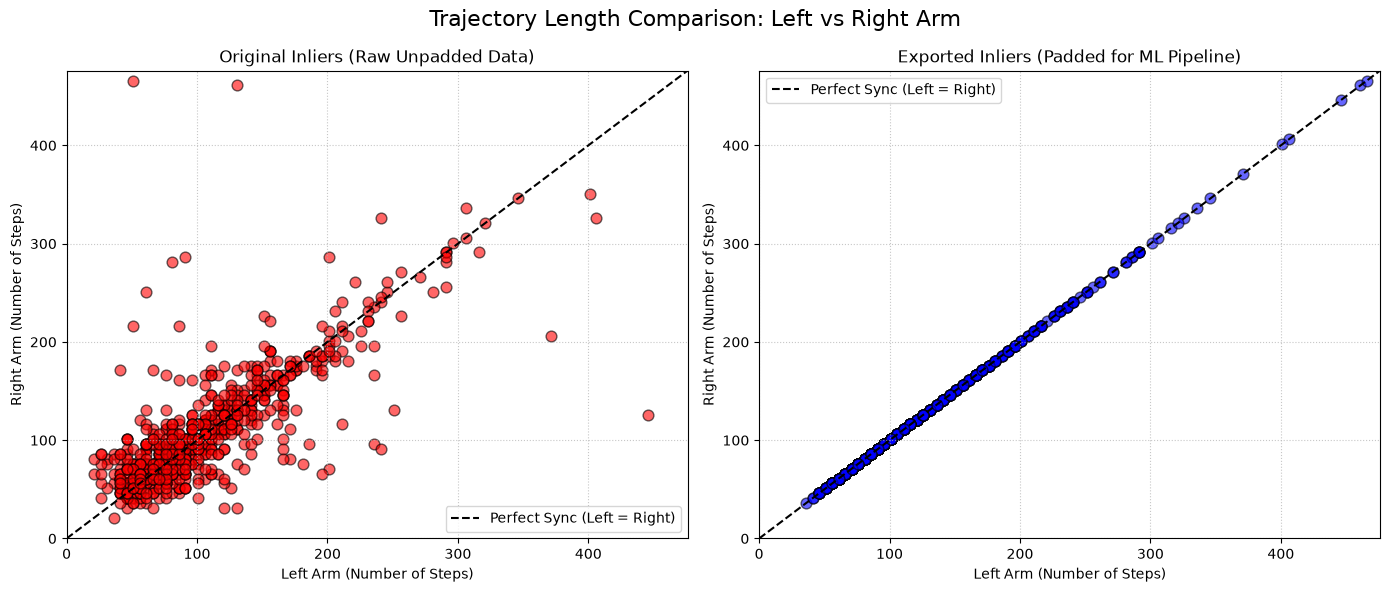

In [44]:
# Load padded inliers (Exported via ML pipeline)
df_inliers_left = read_files(
    glob.glob(f'{Configs.SEPARATED_INLIERS_UMAP_DIR}/*_left_Tasks.csv')
)
df_inliers_right = read_files(
    glob.glob(f'{Configs.SEPARATED_INLIERS_UMAP_DIR}/*_right_Tasks.csv')
)

# Load original raw files
df_original_left = read_files(Configs.SMART_RETAIL_LEFT_FILES)
df_original_right = read_files(Configs.SMART_RETAIL_RIGHT_FILES)

# Filter the original dataset using an INNER JOIN based on valid inliers
inliers_metadata = pd.concat([
    df_inliers_left[['sub', 'repID']], 
    df_inliers_right[['sub', 'repID']]
], ignore_index=True).drop_duplicates()

df_original_left_filtered = pd.merge(df_original_left, inliers_metadata, on=['sub', 'repID'], how='inner')
df_original_right_filtered = pd.merge(df_original_right, inliers_metadata, on=['sub', 'repID'], how='inner')

# Generate the side-by-side plot
plot_arm_steps_comparison(
    df_orig_left=df_original_left_filtered,
    df_orig_right=df_original_right_filtered,
    df_padded_left=df_inliers_left,
    df_padded_right=df_inliers_right
)